In [1]:
import pandas as pd
import numpy as np

# Change this to your Dataset 2 filename
df2 = pd.read_csv("../datasets/dataset2/Digital_Payments_2025_Dataset.csv")

print("Dataset 2 loaded successfully")
print("Shape:", df2.shape)

print("\nColumns:")
print(df2.columns.tolist())

print("\nFirst 5 rows:")
display(df2.head())

print("\nData types:")
print(df2.dtypes)

print("\nMissing values:")
print(df2.isnull().sum())

Dataset 2 loaded successfully
Shape: (620, 7)

Columns:
['PaymentApps', 'CustomerTxCount (Mn)', 'CustomerTxValue (Cr)', 'TotalTxCount (Mn)', 'TotalTxValue (Cr)', 'Period', 'Yr']

First 5 rows:


,PaymentApps,CustomerTxCount (Mn),CustomerTxValue (Cr),TotalTxCount (Mn),TotalTxValue (Cr),Period,Yr
0,Airtel Payments Bank Apps,9.20,2286.20,14.88,5762.90,12,2025
1,Airtel Payments Bank Apps,8.36,1956.05,15.78,5607.35,11,2025
2,Airtel Payments Bank Apps,7.50,1514.50,14.12,4683.90,10,2025
3,Airtel Payments Bank Apps,6.85,1547.45,11.44,3782.80,9,2025
4,Airtel Payments Bank Apps,6.25,1401.69,9.27,2918.28,8,2025



Data types:
PaymentApps                 str
CustomerTxCount (Mn)    float64
CustomerTxValue (Cr)    float64
TotalTxCount (Mn)       float64
TotalTxValue (Cr)       float64
Period                    int64
Yr                        int64
dtype: object

Missing values:
PaymentApps             0
CustomerTxCount (Mn)    0
CustomerTxValue (Cr)    0
TotalTxCount (Mn)       0
TotalTxValue (Cr)       0
Period                  0
Yr                      0
dtype: int64


In [2]:
print("Shape:", df2.shape)
print(df2.columns.tolist())
display(df2.head())
print(df2.dtypes)
print(df2.isnull().sum())

Shape: (620, 7)
['PaymentApps', 'CustomerTxCount (Mn)', 'CustomerTxValue (Cr)', 'TotalTxCount (Mn)', 'TotalTxValue (Cr)', 'Period', 'Yr']


,PaymentApps,CustomerTxCount (Mn),CustomerTxValue (Cr),TotalTxCount (Mn),TotalTxValue (Cr),Period,Yr
0,Airtel Payments Bank Apps,9.20,2286.20,14.88,5762.90,12,2025
1,Airtel Payments Bank Apps,8.36,1956.05,15.78,5607.35,11,2025
2,Airtel Payments Bank Apps,7.50,1514.50,14.12,4683.90,10,2025
3,Airtel Payments Bank Apps,6.85,1547.45,11.44,3782.80,9,2025
4,Airtel Payments Bank Apps,6.25,1401.69,9.27,2918.28,8,2025


PaymentApps                 str
CustomerTxCount (Mn)    float64
CustomerTxValue (Cr)    float64
TotalTxCount (Mn)       float64
TotalTxValue (Cr)       float64
Period                    int64
Yr                        int64
dtype: object
PaymentApps             0
CustomerTxCount (Mn)    0
CustomerTxValue (Cr)    0
TotalTxCount (Mn)       0
TotalTxValue (Cr)       0
Period                  0
Yr                      0
dtype: int64


In [3]:
# ============================================
# DATASET 2 - PREPROCESSING
# ============================================

import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler

print("Original shape:", df2.shape)

# Make a copy
data2 = df2.copy()

# --------------------------------------------
# 1. Convert PaymentApps to numerical features
# --------------------------------------------

payment_apps_encoded = pd.get_dummies(
    data2["PaymentApps"],
    prefix="app",
    dtype=int
)

# --------------------------------------------
# 2. Select numerical features
# --------------------------------------------

numeric_features = [
    "CustomerTxCount (Mn)",
    "CustomerTxValue (Cr)",
    "TotalTxCount (Mn)",
    "TotalTxValue (Cr)",
    "Period",
    "Yr"
]

X_numeric = data2[numeric_features].copy()

# --------------------------------------------
# 3. Combine numerical + encoded features
# --------------------------------------------

X2 = pd.concat(
    [
        X_numeric,
        payment_apps_encoded
    ],
    axis=1
)

print("After encoding:", X2.shape)

# --------------------------------------------
# 4. Check missing values
# --------------------------------------------

print("\nMissing values:")
print(X2.isnull().sum().sum())

# --------------------------------------------
# 5. Scale features
# --------------------------------------------

scaler2 = StandardScaler()

X2_scaled = scaler2.fit_transform(X2)

print("\nAfter scaling:", X2_scaled.shape)

print("\nDataset 2 preprocessing completed successfully!")

Original shape: (620, 7)
After encoding: (620, 72)

Missing values:
0

After scaling: (620, 72)

Dataset 2 preprocessing completed successfully!


In [4]:
print("Original features:")
print(numeric_features)

print("\nEncoded app features:")
print(payment_apps_encoded.columns.tolist())

print("\nFinal feature count:")
print(X2_scaled.shape[1])

Original features:
['CustomerTxCount (Mn)', 'CustomerTxValue (Cr)', 'TotalTxCount (Mn)', 'TotalTxValue (Cr)', 'Period', 'Yr']

Encoded app features:
['app_AU Small Finance Bank App', 'app_Airtel Payments Bank Apps', 'app_Allahabad Bank App', 'app_Amazon Pay', 'app_Andhra Bank App', 'app_Axis Bank Apps', 'app_BHIM', 'app_Bajaj Finserv', 'app_Bank of Baroda Apps', 'app_Bank of India App', 'app_Bank of Maharashtra App', 'app_Canara Bank App', 'app_Central Bank of India App', 'app_Citi Bank App', 'app_City Union Bank App', 'app_Cointab', 'app_Cred', 'app_DBS Digibank App', 'app_Dena Bank App', 'app_Deutsche Bank App', 'app_Dhanlaxmi Bank App', 'app_Federal Bank App', 'app_Fino Payments bank App', 'app_Finshell Pay', 'app_Freecharge', 'app_Goibibo', 'app_Google Pay', 'app_HDFC Bank Apps', 'app_HSBC Bank App', 'app_ICICI Bank Apps', 'app_IDBI Bank App', 'app_IDFC Bank App', 'app_India Post Payments Bank App', 'app_Indian Bank App', 'app_IndusInd Bank App', 'app_Jammu and Kashmir Bank App', '

In [5]:
# ============================================
# DATASET 2 - ISOLATION FOREST
# ============================================

from sklearn.ensemble import IsolationForest
import time

print("Training Isolation Forest...")

start_time = time.time()

# Use a small contamination because anomalies
# are expected to be a minority
isolation_model2 = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

# Train
isolation_model2.fit(X2_scaled)

training_time2 = time.time() - start_time

print("Training completed!")
print(
    "Training time:",
    round(training_time2, 3),
    "seconds"
)

Training Isolation Forest...
Training completed!
Training time: 0.267 seconds


In [6]:
# ============================================
# ISOLATION FOREST PREDICTION
# ============================================

start_prediction = time.time()

# Isolation Forest:
# -1 = anomaly
#  1 = normal

predictions2 = isolation_model2.predict(X2_scaled)

prediction_time2 = time.time() - start_prediction

# Convert to our format:
# 0 = normal
# 1 = anomaly

anomaly2 = (predictions2 == -1).astype(int)

print("Detected anomalies:", anomaly2.sum())

print(
    "Anomaly percentage:",
    round(anomaly2.mean() * 100, 4)
)

print(
    "Prediction time:",
    round(prediction_time2, 3),
    "seconds"
)

Detected anomalies: 31
Anomaly percentage: 5.0
Prediction time: 0.02 seconds


In [7]:
# ============================================
# DATASET 2 - INSPECT ISOLATION FOREST ANOMALIES
# ============================================

results2 = data2.copy()

results2["anomaly"] = anomaly2

results2["anomaly_score"] = (
    isolation_model2.decision_function(X2_scaled)
)

# Get anomalies
anomalies2 = results2[
    results2["anomaly"] == 1
].copy()

print("Total anomalies:", len(anomalies2))

print("\nMost unusual records:")
display(
    anomalies2.sort_values(
        "anomaly_score"
    ).head(20)
)

Total anomalies: 31

Most unusual records:


,PaymentApps,CustomerTxCount (Mn),CustomerTxValue (Cr),TotalTxCount (Mn),TotalTxValue (Cr),Period,Yr,anomaly,anomaly_score
487,PhonePe,2097.20,399154.90,2117.59,399729.67,12,2025,1,-0.083857
488,PhonePe,1925.94,358182.10,1931.55,368975.46,11,2025,1,-0.074214
489,PhonePe,1969.35,361182.90,1963.95,367127.53,10,2025,1,-0.068925
252,Google Pay,1567.04,305137.50,1585.77,303725.12,12,2025,1,-0.064241
490,PhonePe,1653.62,307220.93,1664.84,307293.37,9,2025,1,-0.061452
491,PhonePe,1598.26,299972.27,1655.19,296524.36,8,2025,1,-0.058632
492,PhonePe,1464.79,285221.06,1467.03,285626.97,7,2025,1,-0.056813
253,Google Pay,1460.62,279650.14,1464.23,286564.92,11,2025,1,-0.055849
254,Google Pay,1471.89,285590.66,1436.31,282554.12,10,2025,1,-0.051215
493,PhonePe,1294.32,263999.63,1287.75,260714.12,6,2025,1,-0.049467


In [8]:
# ============================================
# ANOMALIES BY YEAR AND PERIOD
# ============================================

print("Anomalies by Year")
print("=================")

display(
    anomalies2["Yr"].value_counts()
)

print("\nAnomalies by Period")
print("===================")

display(
    anomalies2["Period"].value_counts().sort_index()
)

Anomalies by Year


Yr
2025    31
Name: count, dtype: int64


Anomalies by Period


Period
1     3
2     3
3     3
4     2
5     2
6     2
7     2
8     2
9     3
10    3
11    3
12    3
Name: count, dtype: int64

In [9]:
# ============================================
# DATASET 2 - LOCAL OUTLIER FACTOR (LOF)
# ============================================

from sklearn.neighbors import LocalOutlierFactor
import time

print("Training LOF...")

start_time = time.time()

lof_model2 = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05,
    novelty=False,
    n_jobs=-1
)

# LOF directly fits and predicts
lof_predictions2 = lof_model2.fit_predict(X2_scaled)

training_time_lof2 = time.time() - start_time

# -1 = anomaly
#  1 = normal
lof_anomaly2 = (lof_predictions2 == -1).astype(int)

print("LOF training completed!")
print("Training + prediction time:",
      round(training_time_lof2, 3), "seconds")

print("Detected anomalies:",
      lof_anomaly2.sum())

print("Anomaly percentage:",
      round(lof_anomaly2.mean() * 100, 4))

Training LOF...
LOF training completed!
Training + prediction time: 0.055 seconds
Detected anomalies: 31
Anomaly percentage: 5.0


In [10]:
# ============================================
# LOF ANOMALY RESULTS
# ============================================

lof_results2 = data2.copy()

lof_results2["anomaly"] = lof_anomaly2

# LOF negative_outlier_factor_
lof_results2["lof_score"] = (
    lof_model2.negative_outlier_factor_
)

lof_anomalies2 = lof_results2[
    lof_results2["anomaly"] == 1
].copy()

print("Total LOF anomalies:",
      len(lof_anomalies2))

display(
    lof_anomalies2.sort_values(
        "lof_score"
    ).head(20)
)

Total LOF anomalies: 31


,PaymentApps,CustomerTxCount (Mn),CustomerTxValue (Cr),TotalTxCount (Mn),TotalTxValue (Cr),Period,Yr,anomaly,lof_score
251,Goibibo,0.01,2.59,0.01,2.65,9,2025,1,-2.528513
360,Jammu and Kashmir Bank App,0.01,1.93,0.01,1.96,12,2025,1,-2.528513
471,Other Bank Apps,0.04,16.73,0.04,16.30,7,2025,1,-2.528513
408,Khalijeb,0.02,2.48,0.02,2.53,1,2025,1,-2.528513
35,Andhra Bank App,0.02,13.32,0.02,13.41,1,2025,1,-2.528513
619,WhatsApp,2.25,192.34,2.28,191.29,12,2025,1,-2.528513
250,Freecharge,1.11,63.71,1.10,64.14,1,2025,1,-2.528512
514,Punjab Sindh Bank App,0.01,2.73,0.01,2.75,9,2025,1,-1.814919
515,Punjab Sindh Bank App,0.01,2.56,0.01,2.51,8,2025,1,-1.814919
220,Dhanlaxmi Bank App,0.01,2.34,0.01,2.34,11,2025,1,-1.514698


In [11]:
print("LOF Anomalies by Payment App")
print("=============================")

display(
    lof_anomalies2["PaymentApps"]
    .value_counts()
    .reset_index()
)

LOF Anomalies by Payment App


,PaymentApps,count
0,Finshell Pay,4
1,RealMe,4
2,Dhanlaxmi Bank App,3
3,Others,3
4,Punjab Sind Bank App,3
5,Truecaller,3
6,Janta Sahakari Bank App,2
7,Punjab Sindh Bank App,2
8,Andhra Bank App,1
9,Freecharge,1


In [12]:
# ============================================
# DATASET 2 - ONE-CLASS SVM
# ============================================

from sklearn.svm import OneClassSVM
import time

print("Training One-Class SVM...")

start_time = time.time()

ocsvm_model2 = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.05
)

ocsvm_model2.fit(X2_scaled)

training_time_ocsvm2 = time.time() - start_time

print("One-Class SVM training completed!")
print(
    "Training time:",
    round(training_time_ocsvm2, 3),
    "seconds"
)

Training One-Class SVM...
One-Class SVM training completed!
Training time: 0.007 seconds


In [13]:
# ============================================
# ONE-CLASS SVM PREDICTION
# ============================================

start_prediction = time.time()

ocsvm_predictions2 = ocsvm_model2.predict(X2_scaled)

prediction_time_ocsvm2 = time.time() - start_prediction

# -1 = anomaly
#  1 = normal

ocsvm_anomaly2 = (
    ocsvm_predictions2 == -1
).astype(int)

print(
    "Detected anomalies:",
    ocsvm_anomaly2.sum()
)

print(
    "Anomaly percentage:",
    round(ocsvm_anomaly2.mean() * 100, 4)
)

print(
    "Prediction time:",
    round(prediction_time_ocsvm2, 3),
    "seconds"
)

Detected anomalies: 65
Anomaly percentage: 10.4839
Prediction time: 0.009 seconds


In [14]:
# ============================================
# ONE-CLASS SVM ANOMALY DETAILS
# ============================================

ocsvm_results2 = data2.copy()

ocsvm_results2["anomaly"] = ocsvm_anomaly2

ocsvm_results2["ocsvm_score"] = (
    ocsvm_model2.decision_function(X2_scaled)
)

ocsvm_anomalies2 = ocsvm_results2[
    ocsvm_results2["anomaly"] == 1
].copy()

print(
    "Total One-Class SVM anomalies:",
    len(ocsvm_anomalies2)
)

display(
    ocsvm_anomalies2.sort_values(
        "ocsvm_score"
    ).head(20)
)

Total One-Class SVM anomalies: 65


,PaymentApps,CustomerTxCount (Mn),CustomerTxValue (Cr),TotalTxCount (Mn),TotalTxValue (Cr),Period,Yr,anomaly,ocsvm_score
408,Khalijeb,0.02,2.48,0.02,2.53,1,2025,1,-0.865101
35,Andhra Bank App,0.02,13.32,0.02,13.41,1,2025,1,-0.865101
250,Freecharge,1.11,63.71,1.10,64.14,1,2025,1,-0.865101
360,Jammu and Kashmir Bank App,0.01,1.93,0.01,1.96,12,2025,1,-0.865100
619,WhatsApp,2.25,192.34,2.28,191.29,12,2025,1,-0.865100
251,Goibibo,0.01,2.59,0.01,2.65,9,2025,1,-0.865085
471,Other Bank Apps,0.04,16.73,0.04,16.30,7,2025,1,-0.865081
487,PhonePe,2097.20,399154.90,2117.59,399729.67,12,2025,1,-0.093563
252,Google Pay,1567.04,305137.50,1585.77,303725.12,12,2025,1,-0.055970
246,Finshell Pay,0.06,2.93,0.06,2.89,12,2025,1,-0.005627


In [15]:
# ============================================
# DATASET 2 - Z-SCORE ANOMALY DETECTION
# ============================================

from scipy.stats import zscore
import numpy as np
import time

print("Running Z-Score anomaly detection...")

start_time = time.time()

# Use the numerical transaction statistics
z_features = [
    "CustomerTxCount (Mn)",
    "CustomerTxValue (Cr)",
    "TotalTxCount (Mn)",
    "TotalTxValue (Cr)"
]

Z = zscore(data2[z_features], axis=0)

# Multivariate Z-score magnitude
z_score_value = np.sqrt(
    np.sum(Z ** 2, axis=1)
)

# Threshold
# 95th percentile gives approximately the most
# unusual 5% of observations
z_threshold = np.percentile(
    z_score_value,
    95
)

z_anomaly2 = (
    z_score_value > z_threshold
).astype(int)

z_time2 = time.time() - start_time

print("Z-Score completed!")
print("Threshold:", round(z_threshold, 4))
print("Detected anomalies:", z_anomaly2.sum())
print(
    "Anomaly percentage:",
    round(z_anomaly2.mean() * 100, 4)
)
print(
    "Execution time:",
    round(z_time2, 4),
    "seconds"
)

Running Z-Score anomaly detection...
Z-Score completed!
Threshold: 1.7854
Detected anomalies: 31
Anomaly percentage: 5.0
Execution time: 0.0018 seconds


In [16]:
# ============================================
# Z-SCORE ANOMALY DETAILS
# ============================================

z_results2 = data2.copy()

z_results2["z_score"] = z_score_value
z_results2["anomaly"] = z_anomaly2

z_anomalies2 = z_results2[
    z_results2["anomaly"] == 1
].copy()

print(
    "Total Z-Score anomalies:",
    len(z_anomalies2)
)

display(
    z_anomalies2.sort_values(
        "z_score",
        ascending=False
    ).head(20)
)

Total Z-Score anomalies: 31


,PaymentApps,CustomerTxCount (Mn),CustomerTxValue (Cr),TotalTxCount (Mn),TotalTxValue (Cr),Period,Yr,z_score,anomaly
487,PhonePe,2097.20,399154.90,2117.59,399729.67,12,2025,15.371601,1
489,PhonePe,1969.35,361182.90,1963.95,367127.53,10,2025,14.146326,1
488,PhonePe,1925.94,358182.10,1931.55,368975.46,11,2025,13.990263,1
490,PhonePe,1653.62,307220.93,1664.84,307293.37,9,2025,11.863286,1
491,PhonePe,1598.26,299972.27,1655.19,296524.36,8,2025,11.564390,1
252,Google Pay,1567.04,305137.50,1585.77,303725.12,12,2025,11.493558,1
492,PhonePe,1464.79,285221.06,1467.03,285626.97,7,2025,10.701981,1
253,Google Pay,1460.62,279650.14,1464.23,286564.92,11,2025,10.642717,1
254,Google Pay,1471.89,285590.66,1436.31,282554.12,10,2025,10.632519,1
493,PhonePe,1294.32,263999.63,1287.75,260714.12,6,2025,9.592030,1


In [17]:
print("Z-Score Anomalies by Payment App")
print("=================================")

z_app_summary = (
    z_anomalies2["PaymentApps"]
    .value_counts()
    .reset_index()
)

z_app_summary.columns = [
    "PaymentApps",
    "Anomaly_Count"
]

display(z_app_summary)

Z-Score Anomalies by Payment App


,PaymentApps,Anomaly_Count
0,Google Pay,12
1,PhonePe,12
2,Paytm Payments Bank App,7


In [18]:
# ============================================
# DATASET 2 - HBOS
# ============================================

from pyod.models.hbos import HBOS
import time

print("Training HBOS...")

start_time = time.time()

hbos_model2 = HBOS(
    contamination=0.05,
    n_bins=10
)

hbos_model2.fit(X2_scaled)

training_time_hbos2 = time.time() - start_time

print("HBOS training completed!")
print(
    "Training time:",
    round(training_time_hbos2, 3),
    "seconds"
)

Training HBOS...
HBOS training completed!
Training time: 2.41 seconds


In [19]:
# ============================================
# HBOS PREDICTION
# ============================================

start_prediction = time.time()

hbos_predictions2 = hbos_model2.predict(X2_scaled)

prediction_time_hbos2 = time.time() - start_prediction

# PyOD:
# 0 = normal
# 1 = anomaly

hbos_anomaly2 = hbos_predictions2.astype(int)

print(
    "Detected anomalies:",
    hbos_anomaly2.sum()
)

print(
    "Anomaly percentage:",
    round(hbos_anomaly2.mean() * 100, 4)
)

print(
    "Prediction time:",
    round(prediction_time_hbos2, 4),
    "seconds"
)

Detected anomalies: 31
Anomaly percentage: 5.0
Prediction time: 0.0012 seconds


In [20]:
# ============================================
# HBOS ANOMALY DETAILS
# ============================================

hbos_results2 = data2.copy()

hbos_results2["anomaly"] = hbos_anomaly2

hbos_results2["hbos_score"] = (
    hbos_model2.decision_scores_
)

hbos_anomalies2 = hbos_results2[
    hbos_results2["anomaly"] == 1
].copy()

print(
    "Total HBOS anomalies:",
    len(hbos_anomalies2)
)

display(
    hbos_anomalies2.sort_values(
        "hbos_score",
        ascending=False
    ).head(20)
)

Total HBOS anomalies: 31


,PaymentApps,CustomerTxCount (Mn),CustomerTxValue (Cr),TotalTxCount (Mn),TotalTxValue (Cr),Period,Yr,anomaly,hbos_score
489,PhonePe,1969.35,361182.90,1963.95,367127.53,10,2025,1,4.974539
493,PhonePe,1294.32,263999.63,1287.75,260714.12,6,2025,1,4.949346
255,Google Pay,1277.34,249060.64,1284.04,250436.89,9,2025,1,4.785473
477,Paytm Payments Bank App,539.98,64268.34,643.56,81850.38,10,2025,1,4.785015
256,Google Pay,1230.00,243738.80,1261.19,241344.01,8,2025,1,4.778162
495,PhonePe,1206.44,230560.36,1213.16,234012.96,4,2025,1,4.738712
494,PhonePe,1129.13,233855.30,1127.37,235203.03,5,2025,1,4.717497
254,Google Pay,1471.89,285590.66,1436.31,282554.12,10,2025,1,4.702787
492,PhonePe,1464.79,285221.06,1467.03,285626.97,7,2025,1,4.702787
491,PhonePe,1598.26,299972.27,1655.19,296524.36,8,2025,1,4.696807


In [21]:
# ============================================
# DATASET 2 - MODEL COMPARISON
# ============================================

comparison2 = pd.DataFrame({
    "Model": [
        "Isolation Forest",
        "LOF",
        "One-Class SVM",
        "HBOS",
        "Z-Score"
    ],

    "Anomalies Detected": [
        anomaly2.sum(),
        lof_anomaly2.sum(),
        ocsvm_anomaly2.sum(),
        hbos_anomaly2.sum(),
        z_anomaly2.sum()
    ]
})

comparison2["Anomaly Percentage"] = (
    comparison2["Anomalies Detected"]
    / len(data2)
    * 100
)

print("Dataset 2 - Model Comparison")
print("============================")

display(comparison2)

Dataset 2 - Model Comparison


,Model,Anomalies Detected,Anomaly Percentage
0,Isolation Forest,31,5.000000
1,LOF,31,5.000000
2,One-Class SVM,65,10.483871
3,HBOS,31,5.000000
4,Z-Score,31,5.000000


In [22]:
# ============================================
# DATASET 2 - ENSEMBLE ANOMALY DETECTION
# ============================================

ensemble2 = data2.copy()

ensemble2["IsolationForest"] = anomaly2
ensemble2["LOF"] = lof_anomaly2
ensemble2["OneClassSVM"] = ocsvm_anomaly2
ensemble2["HBOS"] = hbos_anomaly2
ensemble2["ZScore"] = z_anomaly2

# Count how many models agree
ensemble2["anomaly_votes"] = (
    ensemble2["IsolationForest"]
    + ensemble2["LOF"]
    + ensemble2["OneClassSVM"]
    + ensemble2["HBOS"]
    + ensemble2["ZScore"]
)

# At least 3 models must agree
ensemble2["final_anomaly"] = (
    ensemble2["anomaly_votes"] >= 3
).astype(int)

print("======================================")
print("DATASET 2 - ENSEMBLE RESULTS")
print("======================================")

print(
    "Total ensemble anomalies:",
    ensemble2["final_anomaly"].sum()
)

print(
    "Anomaly percentage:",
    round(
        ensemble2["final_anomaly"].mean() * 100,
        2
    ),
    "%"
)

print("\nVote distribution:")

display(
    ensemble2["anomaly_votes"]
    .value_counts()
    .sort_index()
)

print("\nConsensus anomalies:")

display(
    ensemble2[
        ensemble2["final_anomaly"] == 1
    ]
    .sort_values(
        "anomaly_votes",
        ascending=False
    )
    .head(30)
)

DATASET 2 - ENSEMBLE RESULTS
Total ensemble anomalies: 28
Anomaly percentage: 4.52 %

Vote distribution:


anomaly_votes
0    507
1     69
2     16
3     24
4      4
Name: count, dtype: int64


Consensus anomalies:


,PaymentApps,CustomerTxCount (Mn),CustomerTxValue (Cr),TotalTxCount (Mn),TotalTxValue (Cr),Period,Yr,IsolationForest,LOF,OneClassSVM,HBOS,ZScore,anomaly_votes,final_anomaly
252,Google Pay,1567.04,305137.50,1585.77,303725.12,12,2025,1,0,1,1,1,4,1
253,Google Pay,1460.62,279650.14,1464.23,286564.92,11,2025,1,0,1,1,1,4,1
487,PhonePe,2097.20,399154.90,2117.59,399729.67,12,2025,1,0,1,1,1,4,1
475,Paytm Payments Bank App,624.87,70782.69,702.58,86388.66,12,2025,1,0,1,1,1,4,1
256,Google Pay,1230.00,243738.80,1261.19,241344.01,8,2025,1,0,0,1,1,3,1
257,Google Pay,1106.41,232021.95,1109.93,231083.54,7,2025,1,0,0,1,1,3,1
258,Google Pay,974.42,206686.01,966.73,205100.64,6,2025,1,0,0,1,1,3,1
259,Google Pay,865.43,189581.20,876.54,186543.73,5,2025,1,0,0,1,1,3,1
260,Google Pay,917.51,187884.59,905.58,192425.32,4,2025,1,0,0,1,1,3,1
261,Google Pay,973.18,203231.27,964.99,203584.39,3,2025,1,0,0,1,1,3,1


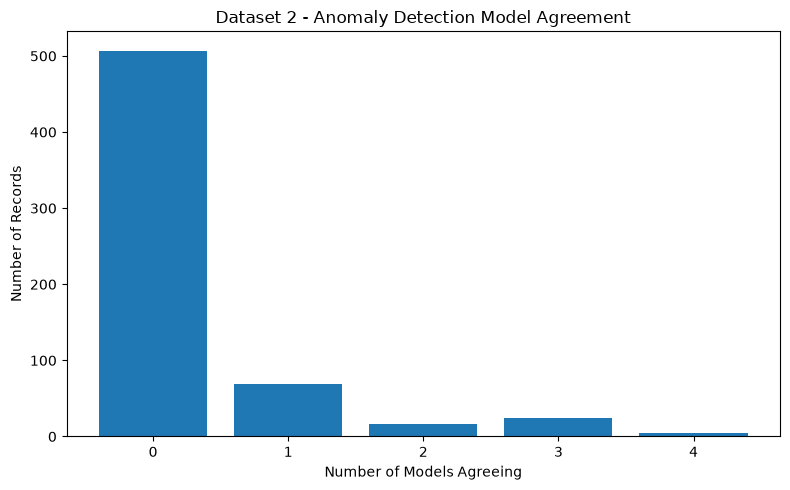

In [23]:
# ============================================
# DATASET 2 - ENSEMBLE VOTE CHART
# ============================================
import matplotlib.pyplot as plt
vote_counts2 = (
    ensemble2["anomaly_votes"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

plt.bar(
    vote_counts2.index.astype(str),
    vote_counts2.values
)

plt.xlabel("Number of Models Agreeing")
plt.ylabel("Number of Records")

plt.title(
    "Dataset 2 - Anomaly Detection Model Agreement"
)

plt.tight_layout()
plt.show()

In [24]:
# ============================================
# SAVE DATASET 2 ENSEMBLE RESULTS
# ============================================

ensemble2.to_csv(
    "../results/dataset2_ensemble_results.csv",
    index=False
)

print("Dataset 2 ensemble results saved successfully!")

Dataset 2 ensemble results saved successfully!


In [25]:
# Find trained Dataset 2 models

from pyod.models.iforest import IForest
from pyod.models.lof import LOF
from pyod.models.ocsvm import OCSVM
from pyod.models.hbos import HBOS

print("Searching for Dataset 2 models...\n")

for name, obj in list(globals().items()):
    try:
        if isinstance(obj, (IForest, LOF, OCSVM, HBOS)):
            print(name, "->", type(obj).__name__)
    except Exception:
        pass

Searching for Dataset 2 models...

hbos_model2 -> HBOS


In [26]:
import os
import joblib

os.makedirs("../models/dataset2", exist_ok=True)

joblib.dump(
    hbos_model2,
    "../models/dataset2/hbos.joblib"
)

print("Dataset 2 HBOS saved successfully!")

Dataset 2 HBOS saved successfully!


In [28]:
# ==========================================
# FIND DATASET 2 MODEL VARIABLES
# ==========================================

print("Searching Dataset 2 variables...\n")

keywords = [
    "iso",
    "isolation",
    "forest",
    "lof",
    "svm",
    "ocsvm",
    "oneclass",
    "model"
]

for name in list(globals().keys()):
    name_lower = name.lower()

    if any(keyword in name_lower for keyword in keywords):
        obj = globals()[name]

        # Don't print huge arrays/dataframes
        if hasattr(obj, "fit") or hasattr(obj, "predict"):
            print("MODEL:", name, "->", type(obj).__name__)
        elif "anomaly" in name_lower or "prediction" in name_lower:
            print("RESULT:", name, "->", type(obj).__name__)

Searching Dataset 2 variables...

MODEL: IsolationForest -> ABCMeta
MODEL: isolation_model2 -> IsolationForest
MODEL: lof_model2 -> LocalOutlierFactor
RESULT: lof_predictions2 -> ndarray
RESULT: lof_anomaly2 -> ndarray
MODEL: OneClassSVM -> ABCMeta
MODEL: ocsvm_model2 -> OneClassSVM
RESULT: ocsvm_predictions2 -> ndarray
RESULT: prediction_time_ocsvm2 -> float
RESULT: ocsvm_anomaly2 -> ndarray
MODEL: hbos_model2 -> HBOS
MODEL: IForest -> ABCMeta
MODEL: LOF -> ABCMeta
MODEL: OCSVM -> ABCMeta


In [29]:
# ============================================================
# DATASET 2 - SAVE ALL TRAINED MODELS
# ============================================================

import os
import joblib
import json

# Create Dataset 2 model directory
os.makedirs("../models/dataset2", exist_ok=True)

# Save Isolation Forest
joblib.dump(
    isolation_model2,
    "../models/dataset2/isolation_forest.joblib"
)

# Save LOF
joblib.dump(
    lof_model2,
    "../models/dataset2/lof.joblib"
)

# Save One-Class SVM
joblib.dump(
    ocsvm_model2,
    "../models/dataset2/one_class_svm.joblib"
)

# Save HBOS
joblib.dump(
    hbos_model2,
    "../models/dataset2/hbos.joblib"
)

print("==========================================")
print("DATASET 2 MODEL EXPORT COMPLETE")
print("==========================================")
print("✓ Isolation Forest saved")
print("✓ LOF saved")
print("✓ One-Class SVM saved")
print("✓ HBOS saved")

DATASET 2 MODEL EXPORT COMPLETE
✓ Isolation Forest saved
✓ LOF saved
✓ One-Class SVM saved
✓ HBOS saved
